# Importações

In [77]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
import subprocess

# C

Roda o executável C para todas as imagens de teste:

In [78]:
# Diretórios
IMAGES_DIR = Path("./images")
C_RESULTS_DIR = Path("./results/c")

# Programa
C_EXECUTABLE = Path("../src/unsharp_mask")

def run_c(input_path, output_path):
    subprocess.run(
        [
            str(C_EXECUTABLE),
            str(input_path),
            str(output_path)
        ],
        check=True
    )

C_RESULTS_DIR.mkdir(parents=True, exist_ok=True)

c_files = sorted(IMAGES_DIR.glob("*.pgm"))

if not c_files:
    print(f"Nenhuma imagem .pgm encontrada em: {IMAGES_DIR}")

for image_path in c_files:

    output_name = image_path.stem + "_result.pgm"

    c_output = C_RESULTS_DIR / output_name

    print(f"Processando:   {image_path.name}")

    try:
        run_c(image_path, c_output)

        print("  ✓ OK\n")

    except subprocess.CalledProcessError as error:
        print(f"  ✗ Erro ao processar {image_path.name}")
        print(f"    Código de saída: {error.returncode}\n")

print("Pipeline finalizado.")

Processando:   barb.pgm
  ✓ OK

Processando:   boat.pgm
  ✓ OK

Processando:   goldhill2.pgm
  ✓ OK

Processando:   lena2.pgm
  ✓ OK

Processando:   library.pgm
  ✓ OK

Processando:   mandrill.pgm
  ✓ OK

Processando:   mona_lisa.pgm
  ✓ OK

Processando:   peppers2.pgm
  ✓ OK

Processando:   washsat.pgm
  ✓ OK

Processando:   zelda.pgm
  ✓ OK

Pipeline finalizado.


# Python

Roda o script python, contendo a implementação de referência da lib Kornia, para todas as imagens de teste:

In [79]:
IMAGES_DIR = Path("./images")
KORNIA_RESULTS_DIR = Path("./results/kornia")

KORNIA_SCRIPT = Path("../src/unsharp_mask.py")

def run_kornia(input_path, output_path):
    subprocess.run(
        [
            "python3",
            str(KORNIA_SCRIPT),
            str(input_path),
            str(output_path)
        ],
        check=True
    )

KORNIA_RESULTS_DIR.mkdir(parents=True, exist_ok=True)

kornia_files = sorted(IMAGES_DIR.glob("*.pgm"))

if not kornia_files:
    print(f"Nenhuma imagem .pgm encontrada em: {IMAGES_DIR}")

for image_path in kornia_files:

    output_name = image_path.stem + "_result.pgm"

    kornia_output = KORNIA_RESULTS_DIR / output_name

    print(f"Processando:   {image_path.name}")

    try:
        run_kornia(image_path, kornia_output)

        print("  ✓ OK\n")

    except subprocess.CalledProcessError as error:
        print(f"  ✗ Erro ao processar {image_path.name}")
        print(f"    Código de saída: {error.returncode}\n")

print("Pipeline finalizado.")

Processando:   barb.pgm


/home/antonio/Documentos/projetos/unsharp-masking/.venv/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


  ✓ OK

Processando:   boat.pgm


/home/antonio/Documentos/projetos/unsharp-masking/.venv/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


  ✓ OK

Processando:   goldhill2.pgm


...

  ✓ OK

Processando:   washsat.pgm


/home/antonio/Documentos/projetos/unsharp-masking/.venv/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


  ✓ OK

Processando:   zelda.pgm


/home/antonio/Documentos/projetos/unsharp-masking/.venv/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


  ✓ OK

Pipeline finalizado.


# Testes

In [80]:
def comparar_imagens(caminho_original, caminho_c, caminho_kornia):

    original = cv2.imread(
        str(caminho_original),
        cv2.IMREAD_GRAYSCALE
    )

    imagem_c = cv2.imread(
        str(caminho_c),
        cv2.IMREAD_GRAYSCALE
    )

    imagem_kornia = cv2.imread(
        str(caminho_kornia),
        cv2.IMREAD_GRAYSCALE
    )

    if original is None:
        raise ValueError(f"Não foi possível ler {caminho_original}")

    if imagem_c is None:
        raise ValueError(f"Não foi possível ler {caminho_c}")

    if imagem_kornia is None:
        raise ValueError(f"Não foi possível ler {caminho_kornia}")

    if imagem_c.shape != imagem_kornia.shape:
        raise ValueError(
            f"Dimensões diferentes entre C e Kornia: "
            f"{imagem_c.shape} != {imagem_kornia.shape}"
        )

    c = imagem_c.astype(np.int16)
    kornia = imagem_kornia.astype(np.int16)

    diferenca = np.abs(c - kornia)

    total_pixels = diferenca.size

    pixels_iguais = np.count_nonzero(diferenca == 0)
    pixels_diferentes = total_pixels - pixels_iguais

    percentual_igual = (
        pixels_iguais / total_pixels
    ) * 100

    mae = np.mean(diferenca)

    rmse = np.sqrt(
        np.mean(diferenca ** 2)
    )

    erro_maximo = np.max(diferenca)

    return {
        "original": original,
        "c": imagem_c,
        "kornia": imagem_kornia,
        "diferenca": diferenca,

        "total_pixels": total_pixels,
        "pixels_iguais": pixels_iguais,
        "pixels_diferentes": pixels_diferentes,

        "percentual_igual": percentual_igual,

        "mae": mae,
        "rmse": rmse,
        "erro_maximo": erro_maximo
    }

In [81]:
arquivos_originais = {
    arquivo.name: arquivo for arquivo in sorted(IMAGES_DIR.glob("*.pgm"))
}

arquivos_c = {
    arquivo.name: arquivo for arquivo in sorted(C_RESULTS_DIR.glob("*.pgm"))
}

arquivos_kornia = {
    arquivo.name: arquivo for arquivo in sorted(KORNIA_RESULTS_DIR.glob("*.pgm"))
}

nomes = sorted(arquivos_originais.keys())

comparacoes = {}
resultados = []

for nome in nomes:
    nome_resultado = Path(nome).stem + "_result.pgm"

    resultado = comparar_imagens(
        arquivos_originais[nome],
        arquivos_c[nome_resultado],
        arquivos_kornia[nome_resultado]
    )

    comparacoes[nome] = resultado

    resultados.append({
        "Imagem": nome,
        "Pixels iguais": resultado["pixels_iguais"],
        "% igual": resultado["percentual_igual"],
        "MAE": resultado["mae"],
        "RMSE": resultado["rmse"],
        "Erro máximo": resultado["erro_maximo"]
    })

df_resultados = pd.DataFrame(resultados)

df_resultados

,Imagem,Pixels iguais,% igual,MAE,RMSE,Erro máximo
0,barb.pgm,262144,100.0,0.0,0.0,0
1,boat.pgm,262144,100.0,0.0,0.0,0
2,goldhill2.pgm,262144,100.0,0.0,0.0,0
3,lena2.pgm,262144,100.0,0.0,0.0,0
4,library.pgm,163328,100.0,0.0,0.0,0
5,mandrill.pgm,262144,100.0,0.0,0.0,0
6,mona_lisa.pgm,90000,100.0,0.0,0.0,0
7,peppers2.pgm,262144,100.0,0.0,0.0,0
8,washsat.pgm,262144,100.0,0.0,0.0,0
9,zelda.pgm,262144,100.0,0.0,0.0,0


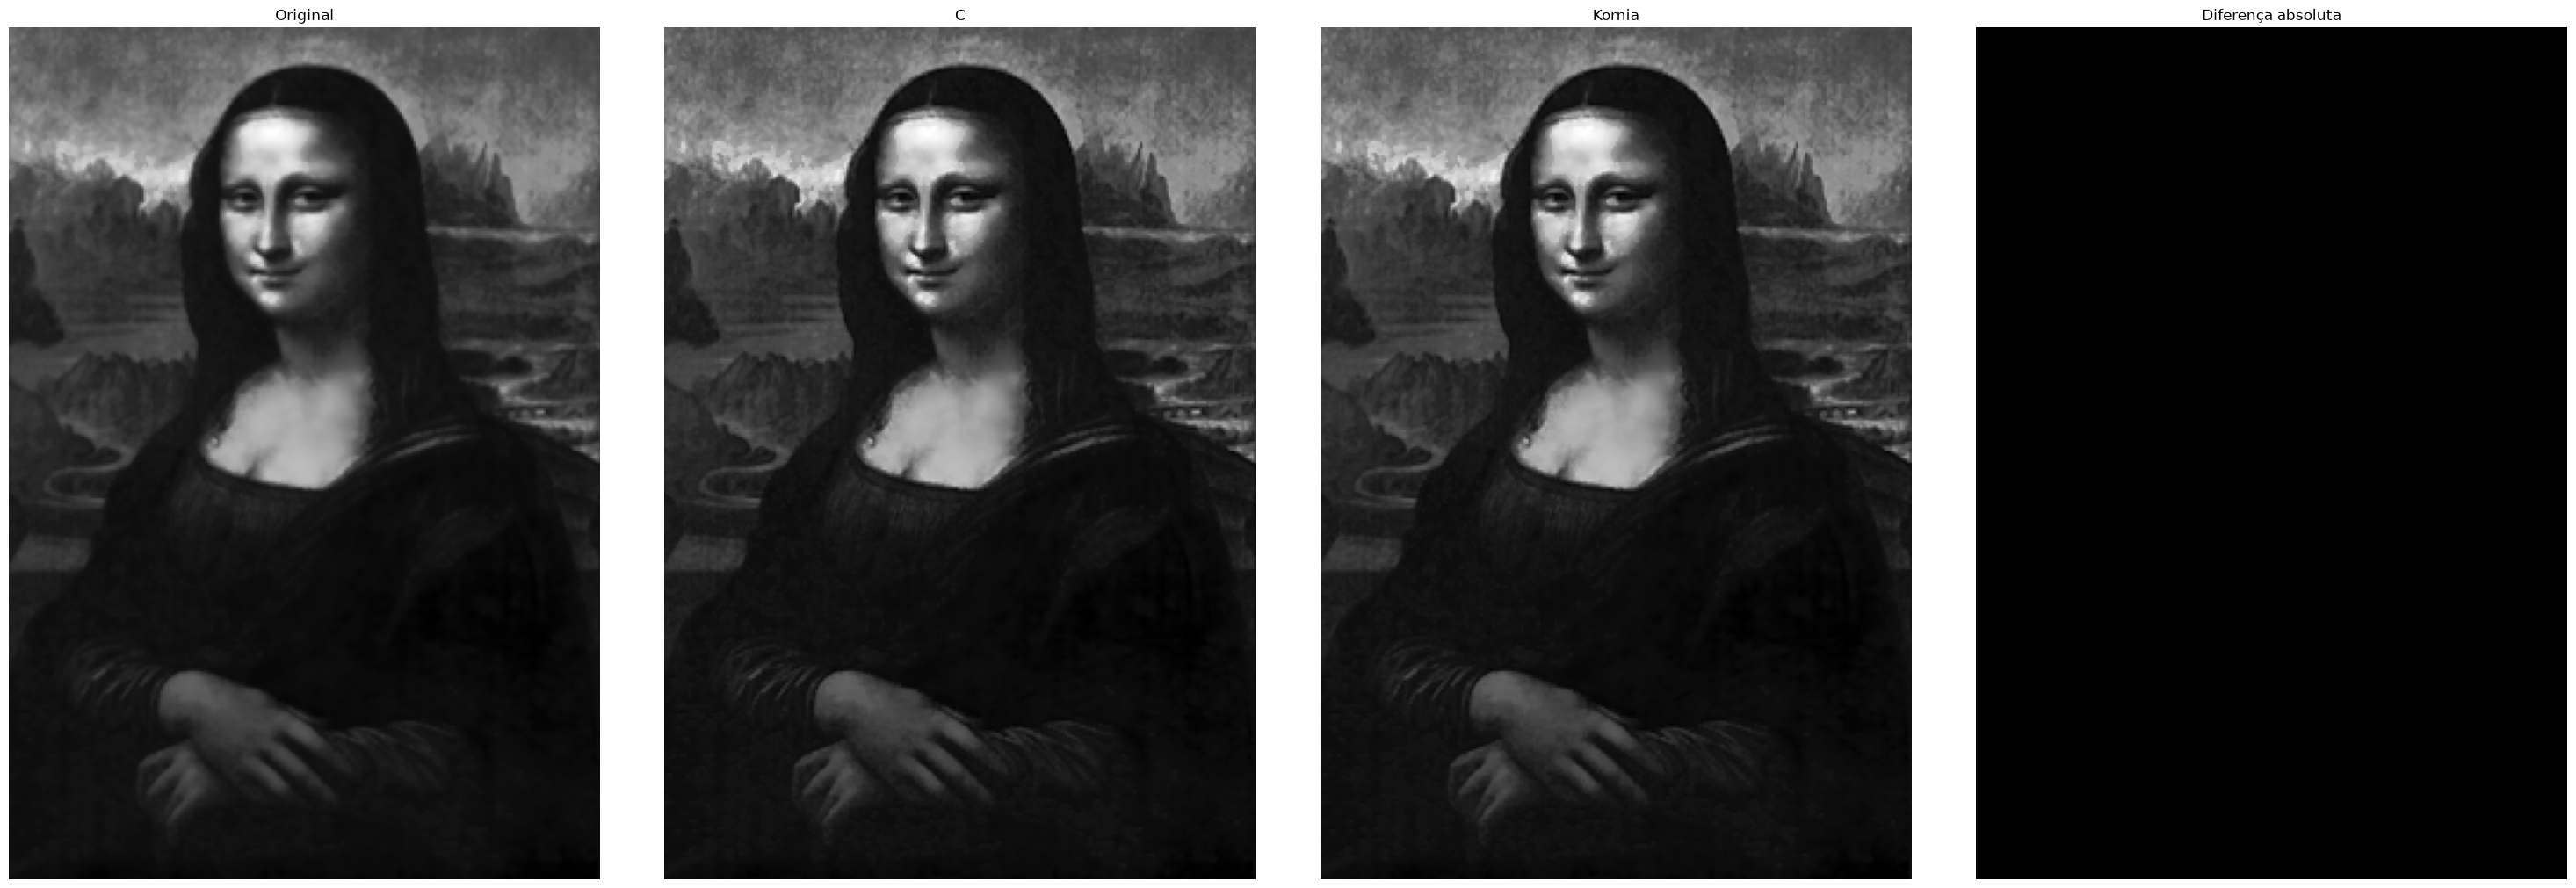

In [85]:

nome_imagem = "mona_lisa.pgm"

resultado = comparacoes[nome_imagem]


fig, axes = plt.subplots(
    1,
    4,
    figsize=(30, 10)
)


# Original
axes[0].imshow(
    resultado["original"],
    cmap="gray",
    vmin=0,
    vmax=255
)

axes[0].set_title("Original")
axes[0].axis("off")


# C
axes[1].imshow(
    resultado["c"],
    cmap="gray",
    vmin=0,
    vmax=255
)

axes[1].set_title("C")
axes[1].axis("off")


# Kornia
axes[2].imshow(
    resultado["kornia"],
    cmap="gray",
    vmin=0,
    vmax=255
)

axes[2].set_title("Kornia")
axes[2].axis("off")


# Diferença
axes[3].imshow(
    resultado["diferenca"],
    cmap="gray",
    vmin=0,
    vmax=max(1, resultado["erro_maximo"])
)

axes[3].set_title("Diferença absoluta")
axes[3].axis("off")


plt.tight_layout()
plt.show()

In [86]:
# ============================================================
# ANÁLISE DOS ERROS
# ============================================================

imagens_com_diferenca = df_resultados[
    df_resultados["Erro máximo"] > 0
]

if imagens_com_diferenca.empty:

    print("Nenhuma diferença encontrada.")
    print("Todas as imagens são pixel-a-pixel idênticas.")

else:

    print("Foram encontradas diferenças nas seguintes imagens:")
    display(imagens_com_diferenca)

    for nome in imagens_com_diferenca["Imagem"]:

        resultado = comparacoes[nome]

        diferenca = resultado["diferenca"]

        valores, quantidades = np.unique(
            diferenca[diferenca > 0],
            return_counts=True
        )

        plt.figure(figsize=(8, 4))

        plt.bar(valores, quantidades)

        plt.xlabel("Erro absoluto")
        plt.ylabel("Quantidade de pixels")
        plt.title(f"Distribuição dos erros — {nome}")

        plt.show()

Nenhuma diferença encontrada.
Todas as imagens são pixel-a-pixel idênticas.


In [87]:
# ============================================================
# 7. RESUMO FINAL
# ============================================================

total_imagens = len(comparacoes)

total_pixels = sum(
    r["total_pixels"]
    for r in comparacoes.values()
)

pixels_iguais = sum(
    r["pixels_iguais"]
    for r in comparacoes.values()
)

pixels_diferentes = sum(
    r["pixels_diferentes"]
    for r in comparacoes.values()
)

percentual_global = (
    pixels_iguais / total_pixels
) * 100

imagens_identicas = sum(
    r["erro_maximo"] == 0
    for r in comparacoes.values()
)

imagens_diferentes = (
    total_imagens - imagens_identicas
)

maior_erro = max(
    r["erro_maximo"]
    for r in comparacoes.values()
)


print("=" * 50)
print("RESULTADO FINAL DOS TESTES")
print("=" * 50)

print(f"Imagens testadas:          {total_imagens}")
print(f"Imagens idênticas:         {imagens_identicas}")
print(f"Imagens diferentes:        {imagens_diferentes}")
print()
print(f"Pixels comparados:         {total_pixels}")
print(f"Pixels idênticos:          {pixels_iguais}")
print(f"Pixels diferentes:         {pixels_diferentes}")
print(f"Taxa global de igualdade:  {percentual_global:.6f}%")
print()
print(f"Maior erro encontrado:     {maior_erro}")

print("=" * 50)

RESULTADO FINAL DOS TESTES
Imagens testadas:          10
Imagens idênticas:         10
Imagens diferentes:        0

Pixels comparados:         2350480
Pixels idênticos:          2350480
Pixels diferentes:         0
Taxa global de igualdade:  100.000000%

Maior erro encontrado:     0
